In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
PROC = Path("../data/processed")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

matches = pd.read_csv(PROC / "matches.csv", dtype={"match_id": str}, parse_dates=["date"])
balls = pd.read_csv(PROC / "balls.csv", dtype={"match_id": str})
print(matches.shape, balls.shape)

(2576, 15) (1366245, 12)


In [2]:
#Investigating the 301
inn_balls = balls.groupby(["match_id", "innings"])["legal_ball_no"].max()
print("Innings over 300 legal balls:", (inn_balls > 300).sum())
print(inn_balls[inn_balls > 300])

Innings over 300 legal balls: 17
match_id  innings
1022373   1          301
1144512   1          301
1271627   1          301
1272379   1          301
1339596   1          301
1377746   1          301
1450697   1          301
247475    1          301
247493    1          301
257470    2          301
258475    1          301
264071    1          301
289110    2          301
291368    1          301
503363    1          301
64832     1          301
65266     1          301
Name: legal_ball_no, dtype: int64


In [3]:
# Who batted first (from the ball data — more reliable than inferring from the toss)
first_bat = balls[balls["innings"] == 1].groupby("match_id")["batting_team"].first()
matches["bat_first"] = matches["match_id"].map(first_bat)
matches["year"] = matches["date"].dt.year

# Innings totals
inn_tot = (balls.groupby(["match_id", "innings"])
                .agg(runs=("runs_total", "sum"), wkts=("wicket", "sum"))
                .reset_index())

clean = matches[
    (matches["result"] == "win") &
    (matches["method"].isna()) &
    (matches["overs_limit"] == 50) &
    (matches["bat_first"].notna())
].copy()
clean["chaser_won"] = clean["winner"] != clean["bat_first"]

first_inn = inn_tot[inn_tot["innings"] == 1].set_index("match_id")["runs"]
clean["first_inn_runs"] = clean["match_id"].map(first_inn)

print(f"Clean matches: {len(clean)} of {len(matches)}")
print(f"Chasing side won: {clean['chaser_won'].mean():.1%}")

Clean matches: 2230 of 2576
Chasing side won: 52.0%


#### Chart 1, scoring by over (the shape of an ODI innings)

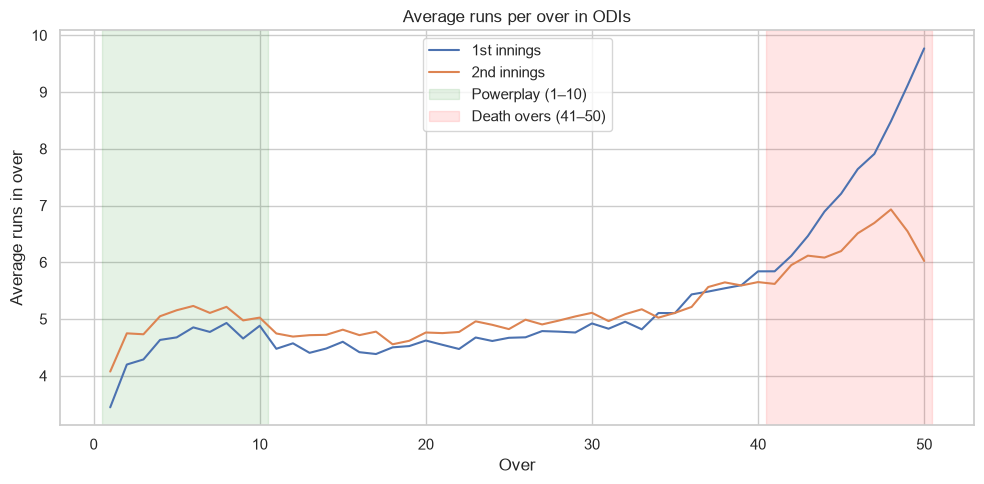

In [4]:
b = balls[balls["match_id"].isin(clean["match_id"]) & (balls["innings"] <= 2)]
per_over = b.groupby(["match_id", "innings", "over"])["runs_total"].sum().reset_index()
avg_over = per_over.groupby(["innings", "over"])["runs_total"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(avg_over.index + 1, avg_over[1], label="1st innings")
ax.plot(avg_over.index + 1, avg_over[2], label="2nd innings")
ax.axvspan(0.5, 10.5, alpha=0.1, color="green", label="Powerplay (1–10)")
ax.axvspan(40.5, 50.5, alpha=0.1, color="red", label="Death overs (41–50)")
ax.set(xlabel="Over", ylabel="Average runs in over", title="Average runs per over in ODIs")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "runs_per_over.png", dpi=150)
plt.show()

#### Chart 2, first-innings totals over time

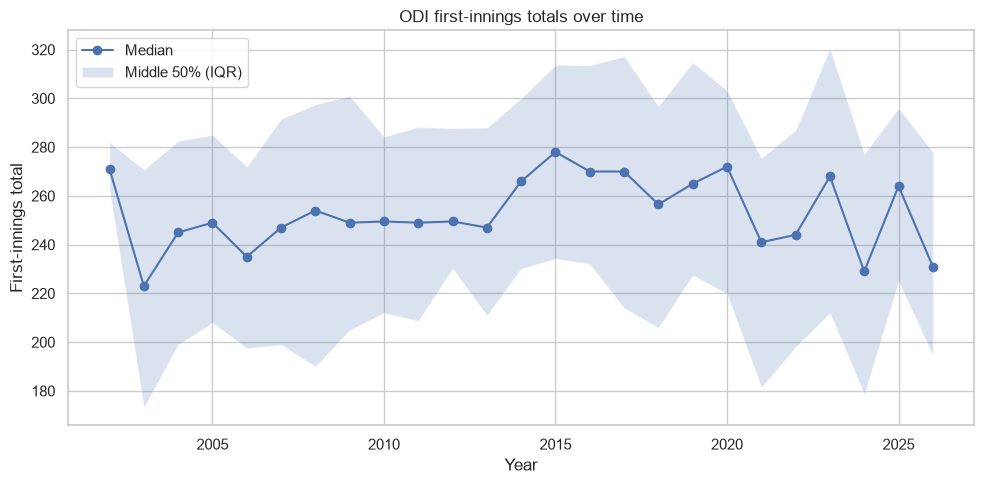

In [5]:
yearly = clean.groupby("year")["first_inn_runs"].describe()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(yearly.index, yearly["50%"], marker="o", label="Median")
ax.fill_between(yearly.index, yearly["25%"], yearly["75%"], alpha=0.2, label="Middle 50% (IQR)")
ax.set(xlabel="Year", ylabel="First-innings total", title="ODI first-innings totals over time")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "totals_over_time.png", dpi=150)
plt.show()

#### Chart 3, chase success by target

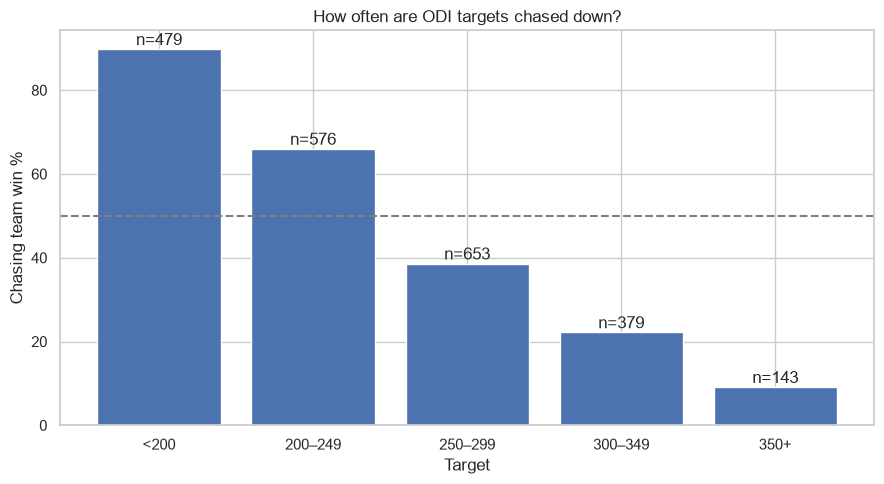

                 mean  count
target_band                 
<200         0.897704    479
200–249      0.659722    576
250–299      0.385911    653
300–349      0.221636    379
350+         0.090909    143


In [6]:
clean["target"] = clean["first_inn_runs"] + 1
bins = [0, 200, 250, 300, 350, 1000]
labels = ["<200", "200–249", "250–299", "300–349", "350+"]
clean["target_band"] = pd.cut(clean["target"], bins=bins, labels=labels, right=False)

chase = clean.groupby("target_band", observed=True)["chaser_won"].agg(["mean", "count"])

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(chase.index.astype(str), chase["mean"] * 100)
for bar, n in zip(bars, chase["count"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, f"n={n}", ha="center")
ax.axhline(50, ls="--", color="grey")
ax.set(xlabel="Target", ylabel="Chasing team win %", title="How often are ODI targets chased down?")
plt.tight_layout()
plt.savefig(FIG / "chase_success_by_target.png", dpi=150)
plt.show()
print(chase)

#### Chart 4, chasing vs. defending over time

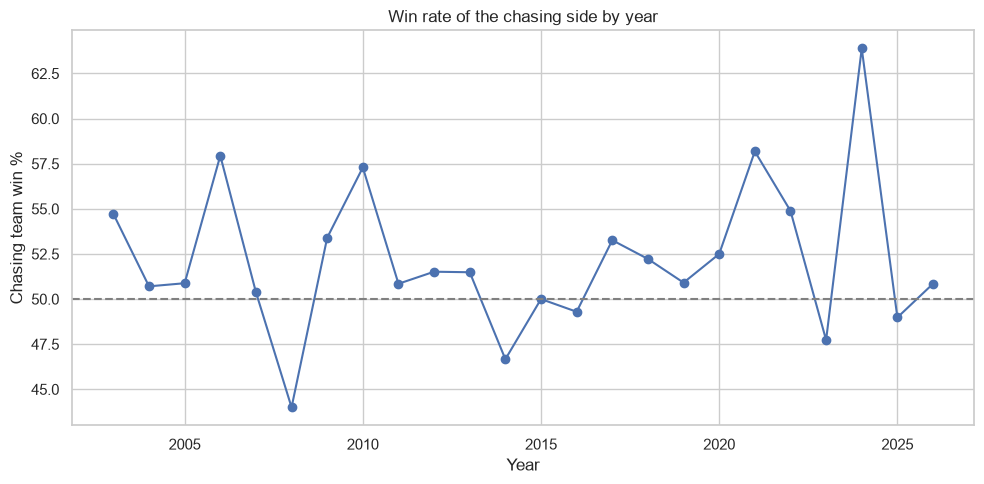

In [7]:
by_year = clean.groupby("year")["chaser_won"].agg(["mean", "count"])
by_year = by_year[by_year["count"] >= 30]   # skip thin years

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(by_year.index, by_year["mean"] * 100, marker="o")
ax.axhline(50, ls="--", color="grey")
ax.set(xlabel="Year", ylabel="Chasing team win %", title="Win rate of the chasing side by year")
plt.tight_layout()
plt.savefig(FIG / "chase_win_rate_by_year.png", dpi=150)
plt.show()